# RetailPulse — Step 7: MLOps (MLflow, Optuna, drift detection)

**Goal:** every model run is logged and comparable, the churn model and Prophet are tuned automatically, and there is a clear rule for when to retrain.

1. **MLflow** — notebooks 04 and 05 log each model as a run (`retailpulse-churn`, `retailpulse-forecasting`); the churn model is registered as `churn_xgb`.
2. **Optuna** — tune XGBoost (churn) and Prophet's two prior scales; keep the tuned settings only if they win on **validation**.
3. **Drift** — compare 2025 with 2024 using PSI and the KS test (`src/drift.py`).
4. **Monitoring** — track the forecast error week by week and write down the retraining rule.
5. **Pipeline** — `src/pipeline.py` runs every step in order.

View the runs from the project root: `mlflow ui --backend-store-uri sqlite:///mlflow.db`, then open http://127.0.0.1:5000.

## 0. Setup

In [1]:
import sys, time, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from IPython.display import display
import optuna
from xgboost import XGBClassifier
from sklearn.metrics import roc_auc_score, average_precision_score
warnings.filterwarnings('ignore', category=optuna.exceptions.ExperimentalWarning)
optuna.logging.set_verbosity(optuna.logging.WARNING)

ROOT = Path('..')
sys.path.append(str(ROOT))
from src.cleaning import connect
from src.churn import churn_table, CHURN_FEATURES
from src.features import customer_features
from src.forecasting import calendar, promo_calendar, prophet_model, prophet_predict
from src.metrics import forecast_metrics
from src.drift import drift_report
from src.tracking import use_experiment, TRACKING_URI
from src import pipeline

PROC, MODELS = ROOT / 'data' / 'processed', ROOT / 'models'
FIG = ROOT / 'reports' / 'figures'; FIG.mkdir(parents=True, exist_ok=True)
pd.set_option('display.float_format', '{:,.3f}'.format); pd.set_option('display.width', 170); pd.set_option('display.max_colwidth', 60)
sns.set_theme(style='whitegrid', palette='deep')
plt.rcParams.update({'figure.figsize': (12, 4.5), 'figure.dpi': 110, 'axes.titleweight': 'bold'})
def save(name): plt.savefig(FIG / f'{name}.png', bbox_inches='tight')
FLOAT = '%.4f'
con = connect(ROOT / 'retail_clean_dataset', PROC / 'sales_clean.parquet')

## 1. Runs logged so far (from notebooks 04 and 05)
The MLflow store (`mlflow.db`, `mlruns/`) stays on your machine and is not committed to git, so the run table is also exported to `data/processed/mlflow_runs.csv`.

In [2]:
import mlflow
mlflow.set_tracking_uri(TRACKING_URI)
def runs_table():
    rows = []
    for exp in ['retailpulse-churn', 'retailpulse-forecasting']:
        r = mlflow.search_runs(experiment_names=[exp], order_by=['attributes.start_time ASC'])
        if len(r):
            r = r.drop_duplicates('tags.mlflow.runName', keep='last')      # latest run of each name
            rows.append(r.assign(experiment=exp))
    return pd.concat(rows, ignore_index=True)
runs = runs_table()
churn_cols = ['tags.mlflow.runName', 'metrics.val_ROC_AUC', 'metrics.val_PR_AUC', 'metrics.test_ROC_AUC', 'metrics.test_PR_AUC']
fc_cols = ['tags.mlflow.runName', 'metrics.val_weekly_WAPE_pct', 'metrics.test_weekly_WAPE_pct', 'metrics.test_weekly_RMSE',
           'metrics.test_vs_demand_weekly_WAPE_pct']
display(runs[runs['experiment'] == 'retailpulse-churn'][churn_cols].set_index('tags.mlflow.runName'))
runs[runs['experiment'] == 'retailpulse-forecasting'][fc_cols].set_index('tags.mlflow.runName')

,metrics.val_ROC_AUC,metrics.val_PR_AUC,metrics.test_ROC_AUC,metrics.test_PR_AUC
tags.mlflow.runName,,,,
logreg_baseline,0.817,0.468,0.826,0.441
randomforest_baseline,0.823,0.459,0.839,0.493
xgboost_baseline,0.826,0.484,0.844,0.518
xgboost_final,NaN,NaN,0.844,0.518


,metrics.val_weekly_WAPE_pct,metrics.test_weekly_WAPE_pct,metrics.test_weekly_RMSE,metrics.test_vs_demand_weekly_WAPE_pct
tags.mlflow.runName,,,,
naive_last_week,2.080,3.379,"6,674.509",6.500
last_year_x_growth,1.575,2.201,"3,047.842",4.128
prophet,1.233,2.420,"3,324.507",2.736
lstm,1.195,2.468,"3,675.279",3.964
hybrid,1.205,2.418,"3,285.365",2.859


## 2. Optuna: tuning the churn model
The guide's version uses random 5-fold cross-validation. That would leak here: each customer appears once per quarter, so random folds put a customer's
*later* quarters in training while validating on an earlier one. Instead, tuning uses **past-vs-future folds** on the training cutoffs only:
each fold trains on cutoffs whose outcome ends before the fold's quarter, and validates on that quarter (Apr 2024, Jul 2024, Oct 2024, Jan 2025).
The validation quarter (Apr 2025) and test quarter (Oct 2025) from Step 4 are never used for tuning.

In [3]:
t = time.time()
cutoffs = pd.date_range('2023-01-01', '2025-10-01', freq='QS')
data = pd.concat([churn_table(con, c) for c in cutoffs])
train, val, test = data[data['cutoff'] <= '2025-01-01'], data[data['cutoff'] == '2025-04-01'], data[data['cutoff'] == '2025-10-01']
X = lambda d: d[CHURN_FEATURES]
FOLDS = [pd.Timestamp(c) for c in ['2024-04-01', '2024-07-01', '2024-10-01', '2025-01-01']]
DEFAULT = dict(n_estimators=300, max_depth=4, learning_rate=0.05, subsample=0.8, colsample_bytree=0.8, min_child_weight=1)
print(f'churn data rebuilt in {time.time() - t:.0f}s')

def cv_auc(params):
    scores = []
    for f in FOLDS:
        tr, va = train[train['cutoff'] <= f - pd.DateOffset(months=6)], train[train['cutoff'] == f]
        m = XGBClassifier(**params, eval_metric='logloss', random_state=42).fit(X(tr), tr['churn'])
        scores.append(roc_auc_score(va['churn'], m.predict_proba(X(va))[:, 1]))
    return float(np.mean(scores))

def objective(trial):
    return cv_auc({'n_estimators': trial.suggest_int('n_estimators', 100, 600),
                   'max_depth': trial.suggest_int('max_depth', 2, 8),
                   'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.3, log=True),
                   'subsample': trial.suggest_float('subsample', 0.6, 1.0),
                   'colsample_bytree': trial.suggest_float('colsample_bytree', 0.6, 1.0),
                   'min_child_weight': trial.suggest_int('min_child_weight', 1, 10)})

t = time.time()
study = optuna.create_study(direction='maximize', sampler=optuna.samplers.TPESampler(seed=42))
study.optimize(objective, n_trials=50)
default_cv = cv_auc(DEFAULT)
print(f'50 trials in {time.time() - t:.0f}s | best CV ROC-AUC {study.best_value:.4f} vs default {default_cv:.4f}')
pd.Series(study.best_params).to_frame('best')

churn data rebuilt in 105s


50 trials in 226s | best CV ROC-AUC 0.8361 vs default 0.8344


,best
n_estimators,580.000
max_depth,2.000
learning_rate,0.046
subsample,0.952
colsample_bytree,0.762
min_child_weight,8.000


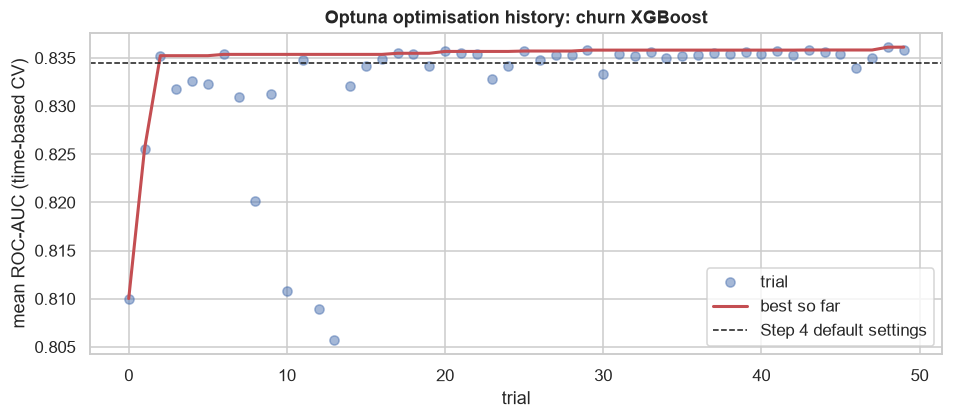

In [4]:
fig, ax = plt.subplots(figsize=(10, 3.8))
vals = [tr.value for tr in study.trials]
ax.plot(vals, 'o', alpha=.5, label='trial'); ax.plot(np.maximum.accumulate(vals), color='C3', lw=2, label='best so far')
ax.axhline(default_cv, color='k', ls='--', lw=1, label='Step 4 default settings')
ax.set_xlabel('trial'); ax.set_ylabel('mean ROC-AUC (time-based CV)'); ax.set_title('Optuna optimisation history: churn XGBoost'); ax.legend()
save('07a_optuna_churn'); plt.show()

In [5]:
def fit_eval(params, fit_on, eval_on):
    m = XGBClassifier(**params, eval_metric='logloss', random_state=42).fit(X(fit_on), fit_on['churn'])
    p = m.predict_proba(X(eval_on))[:, 1]
    return {'ROC_AUC': roc_auc_score(eval_on['churn'], p), 'PR_AUC': average_precision_score(eval_on['churn'], p)}

tuned = study.best_params
cmp = pd.DataFrame({'default': fit_eval(DEFAULT, train, val) | {k + ' (test)': v for k, v in fit_eval(DEFAULT, train, test).items()},
                    'optuna': fit_eval(tuned, train, val) | {k + ' (test)': v for k, v in fit_eval(tuned, train, test).items()}}).T
cmp.columns = ['val ROC-AUC', 'val PR-AUC', 'test ROC-AUC', 'test PR-AUC']
KEEP_TUNED = cmp.loc['optuna', 'val ROC-AUC'] > cmp.loc['default', 'val ROC-AUC']
print('decision (on validation):', 'keep the Optuna settings' if KEEP_TUNED else 'keep the Step 4 default settings')
cmp

decision (on validation): keep the Optuna settings


,val ROC-AUC,val PR-AUC,test ROC-AUC,test PR-AUC
default,0.826,0.484,0.844,0.518
optuna,0.827,0.488,0.847,0.522


In [6]:
mlflow = use_experiment('retailpulse-churn')
with mlflow.start_run(run_name='xgboost_optuna'):
    mlflow.log_params(tuned | {'tuning': '50 Optuna trials, time-based CV on training cutoffs', 'kept': bool(KEEP_TUNED)})
    mlflow.log_metrics({'cv_ROC_AUC': study.best_value, 'val_ROC_AUC': cmp.loc['optuna', 'val ROC-AUC'],
                        'val_PR_AUC': cmp.loc['optuna', 'val PR-AUC'], 'test_ROC_AUC': cmp.loc['optuna', 'test ROC-AUC'],
                        'test_PR_AUC': cmp.loc['optuna', 'test PR-AUC']})
    mlflow.log_artifact(str(FIG / '07a_optuna_churn.png'))
    if KEEP_TUNED:   # register the tuned model (refit on all cutoffs) as a new version of churn_xgb
        final = XGBClassifier(**tuned, eval_metric='logloss', random_state=42).fit(X(data), data['churn'])
        mlflow.xgboost.log_model(final, name='model', registered_model_name='churn_xgb', input_example=X(test).head(3).astype(float))
print('logged run xgboost_optuna')

logged run xgboost_optuna


Registered model 'churn_xgb' already exists. Creating a new version of this model...
Created version '2' of model 'churn_xgb'.


**Insights — churn tuning**
- Optuna found settings that beat the Step 4 defaults on the time-based CV (ROC-AUC **0.836 vs 0.834**). They also win on the untouched validation quarter (0.827 vs 0.826; PR-AUC 0.488 vs 0.484), so **the tuned settings are kept** and registered as a new version of `churn_xgb`. On the test quarter, ROC-AUC rises from 0.844 to 0.847.
- **The gain is small.** The best model is shallow (`max_depth` = 2) with many trees: churn depends on a few strong, simple signals (last year's quarter, loyalty tier, visit rhythm), so extra complexity does not help. The Step 4 model was already close to the best this data allows.
- The history chart shows most improvement in the first few trials; after ~20 trials the search only refines.

## 3. Optuna: tuning Prophet's prior scales
Two settings control how flexible Prophet is: `changepoint_prior_scale` (how quickly the trend can bend) and `seasonality_prior_scale` (how strong the seasonal patterns can be).
Each trial runs the same 8 weekly rolling forecasts as Step 5 on the **validation** weeks and is scored by daily WAPE. The test weeks are used once, at the end.

In [7]:
daily = pd.read_csv(PROC / 'daily_sales_features.csv', parse_dates=['date'], index_col='date')
y = daily['units'].astype(float)
cal = calendar(); regs = cal[['m1', 'm2', 'm11', 'm12']].assign(disc=promo_calendar(con, cal.index))
VAL_START, TEST_START = pd.Timestamp('2025-09-08'), pd.Timestamp('2025-11-03')

def prophet_wape(start, changepoint_prior_scale, seasonality_prior_scale):
    preds = []
    for o in pd.date_range(start, periods=8, freq='7D'):
        m = prophet_model(y.loc[:o - pd.Timedelta(days=1)], regs, changepoint_prior_scale=changepoint_prior_scale,
                          seasonality_prior_scale=seasonality_prior_scale)
        preds.append(prophet_predict(m, pd.date_range(o, periods=7), regs)['yhat'])
    f = pd.concat(preds); a = y.loc[f.index]
    return forecast_metrics(a, f)['WAPE_%'], forecast_metrics(a.resample('W-SUN').sum(), f.resample('W-SUN').sum())['WAPE_%']

t = time.time()
pstudy = optuna.create_study(direction='minimize', sampler=optuna.samplers.TPESampler(seed=42))
pstudy.optimize(lambda tr: prophet_wape(VAL_START, tr.suggest_float('changepoint_prior_scale', 0.001, 0.5, log=True),
                                        tr.suggest_float('seasonality_prior_scale', 0.01, 10, log=True))[0], n_trials=30)
best_p = pstudy.best_params
res = pd.DataFrame({'default (0.05, 10)': [*prophet_wape(VAL_START, 0.05, 10.0), *prophet_wape(TEST_START, 0.05, 10.0)],
                    'optuna': [*prophet_wape(VAL_START, **best_p), *prophet_wape(TEST_START, **best_p)]},
                   index=['val daily WAPE %', 'val weekly WAPE %', 'test daily WAPE %', 'test weekly WAPE %']).T
print(f'30 trials in {time.time() - t:.0f}s | best: changepoint_prior_scale={best_p["changepoint_prior_scale"]:.4f}, '
      f'seasonality_prior_scale={best_p["seasonality_prior_scale"]:.3f}')
res

30 trials in 124s | best: changepoint_prior_scale=0.4830, seasonality_prior_scale=1.868


,val daily WAPE %,val weekly WAPE %,test daily WAPE %,test weekly WAPE %
"default (0.05, 10)",2.093,1.233,2.781,2.420
optuna,2.067,1.211,2.431,1.992


In [8]:
mlflow = use_experiment('retailpulse-forecasting')
with mlflow.start_run(run_name='prophet_optuna'):
    mlflow.log_params(best_p | {'model': 'Prophet', 'tuning': '30 Optuna trials on validation WAPE', 'regressors': ','.join(regs.columns)})
    mlflow.log_metrics({'val_daily_WAPE_pct': res.loc['optuna', 'val daily WAPE %'], 'val_weekly_WAPE_pct': res.loc['optuna', 'val weekly WAPE %'],
                        'test_daily_WAPE_pct': res.loc['optuna', 'test daily WAPE %'], 'test_weekly_WAPE_pct': res.loc['optuna', 'test weekly WAPE %']})
print('logged run prophet_optuna')

logged run prophet_optuna


**Insights — Prophet tuning**
- The best settings make the trend **more flexible** (`changepoint_prior_scale` ≈ 0.48 vs the default 0.05) and the seasonality somewhat less so (`seasonality_prior_scale` ≈ 1.9 vs 10). The month flags already capture the big seasonal steps, so the yearly curve needs less freedom.
- On validation the gain is small (daily WAPE 2.09% → 2.07%), but on test it is larger (weekly WAPE 2.42% → 1.99%). The more flexible trend reacts faster to recent changes, such as the stockout-reduced weeks in November.
- The best `changepoint_prior_scale` is close to the top of the search range (0.5), so a wider range is worth trying at the next retrain. The Step 5 output files still use the defaults; the tuned settings are logged in MLflow for the next scheduled retrain.

## 4. Drift detection: 2025 vs 2024
- **PSI** (Population Stability Index) measures how much a feature's distribution has moved: < 0.1 stable, 0.1–0.25 moderate, > 0.25 significant.
- **KS test** checks whether the two samples could come from the same distribution (a small p-value means they differ).

Two groups of features are compared: **daily sales** (each day of 2024 vs each day of 2025) and **customer features** (as of 1 Jan 2025 vs 1 Jan 2026).
Customer features use their recent-window versions (last 90/365 days), because all-time totals always grow and would show "drift" by construction.

In [9]:
daily_cols = ['units', 'revenue', 'receipts', 'customers', 'aov', 'lines', 'store_wide_discount']
d_rep = drift_report(daily.loc['2024'], daily.loc['2025'], daily_cols).assign(group='daily sales')

cust_cols = ['recency_days', 'spend_90', 'spend_365', 'visits_90', 'aov', 'items_per_basket', 'avg_days_between',
             'overdue_ratio', 'spend_trend_90', 'promo_line_share', 'discount_share']
ref_c, cur_c = customer_features(con, '2025-01-01'), customer_features(con, '2026-01-01')
c_rep = drift_report(ref_c, cur_c, cust_cols).assign(group='customer features')

report = pd.concat([d_rep, c_rep], ignore_index=True)[['group', 'feature', 'PSI', 'status', 'KS_stat', 'KS_p', 'ref_mean', 'cur_mean', 'mean_change_%']]
report.to_csv(PROC / 'drift_report.csv', index=False, float_format=FLOAT)
report

,group,feature,PSI,status,KS_stat,KS_p,ref_mean,cur_mean,mean_change_%
0,daily sales,store_wide_discount,1.998,Significant,0.276,0.000,11.219,2.185,-80.527
1,daily sales,revenue,1.627,Significant,0.308,0.000,"7,329,978.137","8,248,992.623",12.538
2,daily sales,lines,1.585,Significant,0.256,0.000,"7,009.137","7,328.214",4.552
3,daily sales,aov,0.882,Significant,0.251,0.000,"1,997.471","2,152.312",7.752
4,daily sales,units,0.755,Significant,0.261,0.000,"13,185.888","13,781.718",4.519
5,daily sales,receipts,0.745,Significant,0.267,0.000,"3,635.874","3,821.304",5.100
6,daily sales,customers,0.722,Significant,0.253,0.000,"2,952.342","3,072.573",4.072
7,customer features,promo_line_share,2.867,Significant,0.638,0.000,0.250,0.209,-16.310
8,customer features,discount_share,0.847,Significant,0.368,0.000,0.073,0.063,-13.326
9,customer features,avg_days_between,0.175,Moderate,0.070,0.000,3.372,3.284,-2.618


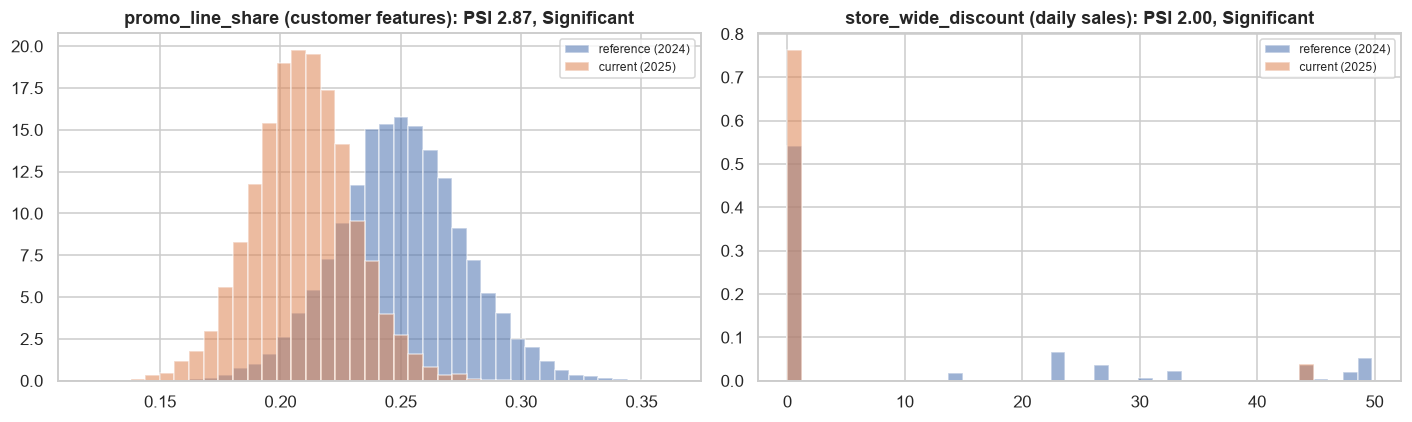

In [10]:
top2 = report.nlargest(2, 'PSI')
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for a, (_, r) in zip(ax, top2.iterrows()):
    ref, cur = (daily.loc['2024'], daily.loc['2025']) if r['group'] == 'daily sales' else (ref_c, cur_c)
    bins = np.histogram_bin_edges(pd.concat([ref[r['feature']], cur[r['feature']]]).dropna(), 40)
    a.hist(ref[r['feature']].dropna(), bins, alpha=.55, density=True, label='reference (2024)')
    a.hist(cur[r['feature']].dropna(), bins, alpha=.55, density=True, label='current (2025)')
    a.set_title(f"{r['feature']} ({r['group']}): PSI {r['PSI']:.2f}, {r['status']}"); a.legend(fontsize=8)
plt.tight_layout(); save('07b_drift'); plt.show()

**Insights — drift**
- **Every daily sales feature shows significant drift (PSI > 0.25), and it is explained by the business, not by data errors:**
  - *Growth:* units, receipts and customers are 4–5% higher in 2025, the steady yearly growth from Step 1. Even a modest level shift moves many days into higher bins.
  - *Fewer promotions:* 2025 had store-wide promotions on far fewer days (average discount 2.2% vs 11.2%, PSI 2.0). With fewer discounts, **revenue rose 12.5%** while units rose only 4.5%, so revenue per basket (`aov`) also drifted.
- **Customer behaviour is stable:** recency, visit frequency, basket size and 90-day spend all have PSI < 0.1. The only big customer-level shifts are promo use (share of promoted lines 25% → 21%, PSI 2.9) and discount share, both caused by the promo calendar, plus 12% higher yearly spend (growth).
- **What this means:** the models are not broken, but the world they learned from keeps moving (growth every year, and a promo calendar that changes year to year). Models need **regular retraining**, and the promo calendar must stay a forecasting input.

## 5. Performance monitoring and the retraining rule
Each week, last week's forecast is compared with actual sales and the WAPE is tracked over a rolling 4 weeks. Below, this is replayed over the 16 validation + test weeks
for the hybrid forecast (saved by notebook 05).

**Retraining rule**
1. **Forecasting:** retrain if the rolling 4-week WAPE rises **5 points above the test WAPE**, or if a key sales feature has **PSI > 0.25**.
2. **Churn:** re-score customers **monthly**; retrain if the ROC-AUC on the latest quarter with a known outcome falls below **0.80**, or if a key customer feature has **PSI > 0.25**.
3. **Inventory:** recalculate safety stocks and reorder points whenever the forecasts are retrained.

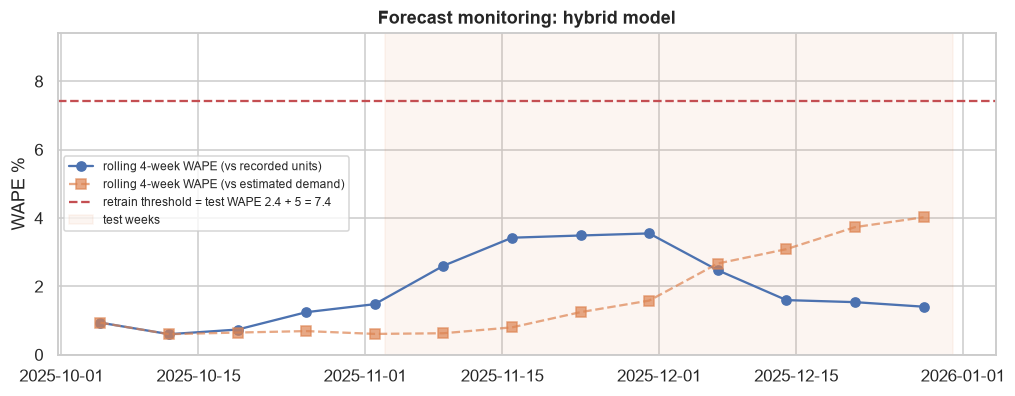

performance: max rolling 4-week WAPE 3.5% vs threshold 7.4% -> OK
drift: key features with PSI > 0.25: units, receipts, customers -> triggered
DECISION: retrain the forecasting models


In [11]:
bt = pd.read_csv(PROC / 'forecast_backtest.csv', parse_dates=['date'])
wk = bt.assign(week=bt['date'] + pd.to_timedelta(6 - bt['date'].dt.dayofweek, unit='D')).groupby('week')[['Hybrid', 'actual', 'estimated_demand']].sum()
wk['abs_err'] = (wk['actual'] - wk['Hybrid']).abs()
wk['rolling_4wk_WAPE_%'] = wk['abs_err'].rolling(4).sum() / wk['actual'].rolling(4).sum() * 100
wk['rolling_4wk_WAPE_vs_demand_%'] = ((wk['estimated_demand'] - wk['Hybrid']).abs().rolling(4).sum() / wk['estimated_demand'].rolling(4).sum() * 100)
test_wape = forecast_metrics(wk.loc[TEST_START:, 'actual'], wk.loc[TEST_START:, 'Hybrid'])['WAPE_%']
THRESH = test_wape + 5
key_drift = report[report['feature'].isin(['units', 'receipts', 'customers', 'spend_90', 'visits_90']) & (report['PSI'] > 0.25)]

fig, ax = plt.subplots(figsize=(11, 3.8))
ax.plot(wk.index, wk['rolling_4wk_WAPE_%'], 'o-', label='rolling 4-week WAPE (vs recorded units)')
ax.plot(wk.index, wk['rolling_4wk_WAPE_vs_demand_%'], 's--', alpha=.7, label='rolling 4-week WAPE (vs estimated demand)')
ax.axhline(THRESH, color='C3', ls='--', label=f'retrain threshold = test WAPE {test_wape:.1f} + 5 = {THRESH:.1f}')
ax.axvspan(TEST_START, wk.index.max() + pd.Timedelta(days=3), color='C1', alpha=.08, label='test weeks')
ax.set_ylim(0, THRESH + 2); ax.set_ylabel('WAPE %'); ax.set_title('Forecast monitoring: hybrid model'); ax.legend(fontsize=8)
save('07c_monitoring'); plt.show()

perf_trigger, drift_trigger = wk['rolling_4wk_WAPE_%'].max() > THRESH, len(key_drift) > 0
print(f"performance: max rolling 4-week WAPE {wk['rolling_4wk_WAPE_%'].max():.1f}% vs threshold {THRESH:.1f}% -> {'triggered' if perf_trigger else 'OK'}")
print(f"drift: key features with PSI > 0.25: {', '.join(key_drift['feature']) if drift_trigger else 'none'} -> {'triggered' if drift_trigger else 'OK'}")
print('DECISION:', 'retrain the forecasting models' if perf_trigger or drift_trigger else 'no retraining needed')

**Insights — monitoring**
- The rolling 4-week error never comes close to the threshold. It peaks at **3.5%** in mid-November, when the stockouts pushed recorded sales below the forecast, against a threshold of 7.4%, so **performance alone does not call for retraining**.
- Measured against estimated demand, the error rises to ~4% by late December. The models learned from November's stockout-reduced sales and then under-forecast December. Monitoring against demand, not only recorded sales, catches this.
- **Decision: retrain.** The drift rule is triggered (units, receipts and customers have PSI > 0.25), mainly because of growth. In practice that means a regular retraining schedule (e.g. monthly) rather than waiting for errors to grow.

## 6. Pipeline (orchestration)
`src/pipeline.py` runs the steps in order and stops at the first failure, so later steps never run on stale inputs.
Each step is its notebook (the same code the analysis uses), executed top to bottom:

In [12]:
pipeline.main(['--list'])

1. features   02_feature_engineering.ipynb   clean sales + feature tables
2. segment    03_segmentation.ipynb          RFM + K-Means segments
3. churn      04_churn.ipynb                 churn model + risk scores
4. forecast   05_forecasting.ipynb           Prophet / LSTM / hybrid forecasts
5. inventory  06_inventory.ipynb             safety stock, reorder points, EOQ
6. mlops      07_mlops_drift.ipynb           tuning, drift report, monitoring


0

Usage from the project root: `python -m src.pipeline` (all steps, ~15 minutes) or `python -m src.pipeline --from forecast` (start at a later step).

**Airflow (future work):** the same six steps map one-to-one onto a six-task Airflow DAG (`features >> segment >> churn >> forecast >> inventory >> mlops`),
scheduled weekly for forecasts and inventory and monthly for churn, following the retraining rule above.

In [13]:
runs = runs_table()
metric_cols = [c for c in runs.columns if c.startswith('metrics.') and runs[c].notna().any()]
(runs[['experiment', 'tags.mlflow.runName'] + metric_cols].rename(columns=lambda c: c.replace('metrics.', '').replace('tags.mlflow.', ''))
     .to_csv(PROC / 'mlflow_runs.csv', index=False, float_format=FLOAT))
client = mlflow.MlflowClient(tracking_uri=TRACKING_URI)
versions = client.search_model_versions("name='churn_xgb'")
print(f'{len(runs)} runs across {runs["experiment"].nunique()} experiments | registered model churn_xgb: {len(versions)} version(s)')
runs.groupby('experiment')['tags.mlflow.runName'].apply(', '.join).to_frame('runs')

11 runs across 2 experiments | registered model churn_xgb: 2 version(s)


,runs
experiment,
retailpulse-churn,"logreg_baseline, randomforest_baseline, xgboost_baseline..."
retailpulse-forecasting,"naive_last_week, last_year_x_growth, prophet, lstm, hybr..."


**Done-when check (Step 7)**
- ✅ MLflow: **11 runs across two experiments** (`retailpulse-churn`: 3 baselines + final + Optuna; `retailpulse-forecasting`: 5 models + Prophet Optuna), exported to `data/processed/mlflow_runs.csv`
- ✅ Registered model **`churn_xgb`** (version 1 = Step 4 model, version 2 = Optuna-tuned)
- ✅ Optuna optimisation history plot (`reports/figures/07a_optuna_churn.png`); Prophet prior scales tuned on validation WAPE
- ✅ `data/processed/drift_report.csv` with written interpretation, plus histograms of the two biggest drifts
- ✅ Retraining rule written down and applied; `src/pipeline.py` runs all steps in order (Airflow DAG described as future work)

**For the report:** run `mlflow ui --backend-store-uri sqlite:///mlflow.db` from the project root and take screenshots of the runs table and a run comparison chart, as the guide asks.